<a href="https://colab.research.google.com/github/EgorMehed/ML-homework/blob/main/%D0%A4%D0%86%D0%A2_3_12_%D0%9C%D0%B5%D1%85%D0%B5%D0%B4_%D0%84%D0%B3%D0%BE%D1%80_%D0%9B%D0%91_2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 2.2
## Дослідження та аналіз даних датасету "Titanic"
**Студент:** Мехед Єгор  
**Група:** ФІТ 3-12

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Завантаження даних через kagglehub

In [ ]:
# Завантаження останньої версії датасету з Kaggle
path = kagglehub.dataset_download("mahmoudshogaa/titanic-dataset")
print("Path to dataset files:", path)

# Знаходимо завантажений csv-файл (titanic.csv)
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
file_path = os.path.join(path, csv_files[0]) if csv_files else os.path.join(path, "titanic.csv")

df = pd.read_csv(file_path)
df.head(10)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


# 2. Починаємо аналізувати структуру даних

In [ ]:
print("Розмірність датасету:", df.shape)
df.info()

Розмірність датасету: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# Перевірка пропущених значень
missing = df.isnull().sum()
print("Пропущені значення по стовпцях:")
print(missing[missing > 0])

Пропущені значення по стовпцях:
Age         177
Cabin       687
Embarked      2
dtype: int64


# 3. Обробка пропусків та створення нових колонок (Feature Engineering)

In [ ]:
# 1. Наявність каюти та визначення палуби (Deck)
if 'Cabin' in df.columns:
    df['Has_cabin'] = df['Cabin'].notnull()
    df['Deck'] = df['Cabin'].str[0].fillna('Unknown')
    df = df.drop(columns='Cabin')
else:
    df['Has_cabin'] = False
    df['Deck'] = 'Unknown'

# 2. Заповнення порту Embarked модою
if 'Embarked' in df.columns and df['Embarked'].isnull().any():
    df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
print("Пропусків в Embarked:", df['Embarked'].isnull().sum() if 'Embarked' in df.columns else 0)

Пропусків в Embarked: 0


In [ ]:
# 3. Витягуємо титули з імен пасажирів
df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)

title_mapping = {
    'Mr': 'Mr',
    'Miss': 'Miss',
    'Mrs': 'Mrs',
    'Master': 'Master',
    'Rev': 'Clergy',          # Священники
    'Col': 'Officer',         # Офіцери / військові
    'Major': 'Officer',
    'Capt': 'Officer',
    'Dr': 'Officer',
    'Don': 'Noble',           # Дворянство
    'Sir': 'Noble',
    'Countess': 'Noble',
    'Lady': 'Noble',
    'Jonkheer': 'Noble',
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs'
}
df['Title'] = df['Title'].map(title_mapping).fillna('Other')
print("Розподіл титулів:")
print(df['Title'].value_counts())

Розподіл титулів:
Title
Mr         517
Miss       185
Mrs        126
Master      40
Officer     12
Clergy       6
Noble        5
Name: count, dtype: int64


In [ ]:
# 4. Заповнення віку медіаною по групі [Title, Pclass]
age_medians = df.groupby(['Title', 'Pclass'])['Age'].median()

def fill_age(row):
    if pd.isnull(row['Age']):
        try:
            return age_medians.loc[row['Title'], row['Pclass']]
        except KeyError:
            return df['Age'].median()
    return row['Age']

df['Age'] = df.apply(fill_age, axis=1)
print("Пропусків у колонці Age:", df['Age'].isnull().sum())

Пропусків у колонці Age: 0


In [ ]:
# 5. Родинні зв'язки та розмір сім'ї
df['Family_Size'] = df['SibSp'] + df['Parch'] + 1
df['Is_Alone'] = (df['Family_Size'] == 1).astype(int)
df['AloneStatus'] = df['Is_Alone'].map({1: 'Alone', 0: 'With someone'})

df.loc[df['Family_Size'] == 1, 'FamilyCategory'] = 'Alone'
df.loc[(df['Family_Size'] > 1) & (df['Family_Size'] <= 4), 'FamilyCategory'] = 'Small'
df.loc[df['Family_Size'] > 4, 'FamilyCategory'] = 'Large'

# 6. Вікові групи
def age_group(age):
    if age < 12:
        return 'Child'
    elif age < 18:
        return 'Teen'
    elif age < 60:
        return 'Adult'
    else:
        return 'Senior'

df['AgeGroup'] = df['Age'].apply(age_group)

# 7. Реальний тариф на людину та категорія вартості квитка
df['Fare_Per_Person'] = df['Fare'] / df['Family_Size']
df['Fare_Category'] = pd.qcut(df['Fare_Per_Person'], q=4, labels=['Low', 'Medium', 'High', 'VIP'])

# 8. Текстовий статус виживання
df['Status'] = df['Survived'].map({0: 'Died', 1: 'Survived'})

df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Deck,Title,Family_Size,Is_Alone,AloneStatus,FamilyCategory,AgeGroup,Fare_Per_Person,Fare_Category,Status
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,Unknown,Mr,2,0,With someone,Small,Adult,3.62500,Low,Died
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,C,Mrs,2,0,With someone,Small,Adult,35.64165,VIP,Survived
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,Unknown,Miss,1,1,Alone,Alone,Adult,7.92500,Medium,Survived
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,C,Mrs,2,0,With someone,Small,Adult,26.55000,VIP,Survived
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,Unknown,Mr,1,1,Alone,Alone,Adult,8.05000,Medium,Died
5,6,0,3,"Moran, Mr. James",male,26.0,0,0,330877,8.4583,...,Unknown,Mr,1,1,Alone,Alone,Adult,8.45830,High,Died
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,...,E,Mr,1,1,Alone,Alone,Adult,51.86250,VIP,Died
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,...,Unknown,Master,5,0,With someone,Large,Child,4.21500,Low,Died
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,...,Unknown,Mrs,3,0,With someone,Small,Adult,3.71110,Low,Survived
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,...,Unknown,Mrs,2,0,With someone,Small,Teen,15.03540,High,Survived


# 4. Дослідницький та креативний аналіз

### 4.1. «Кодекс честі»: як виживали священники (Clergy) та офіцери порівняно з іншими

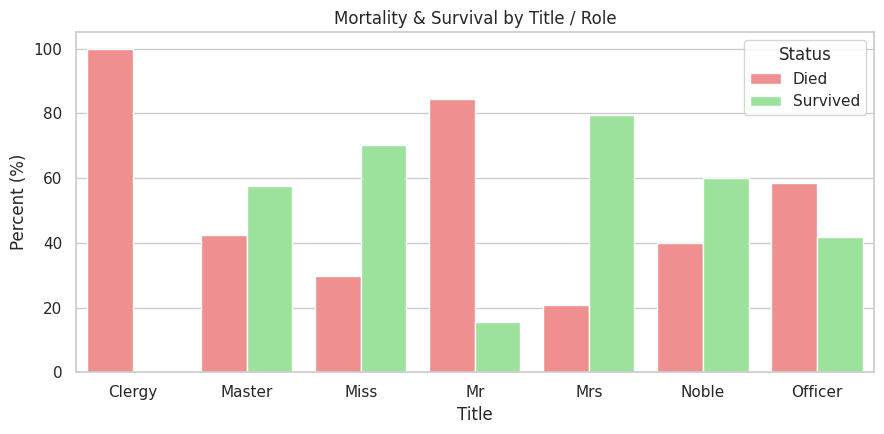

In [ ]:
title_survival = df.groupby(['Title', 'Status']).size().reset_index(name='Count')
title_survival['Percent'] = 100 * title_survival['Count'] / title_survival.groupby('Title')['Count'].transform('sum')

plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=title_survival,
    x='Title',
    y='Percent',
    hue='Status',
    palette=['#ff7f7f', '#90ee90']
)
plt.title('Mortality & Survival by Title / Role')
plt.ylabel('Percent (%)')
plt.xlabel('Title')
plt.tight_layout()
plt.show()

### 4.2. «Гроші проти статі»: чи рятував VIP-тариф чоловіків краще, ніж жінок 3-го класу?

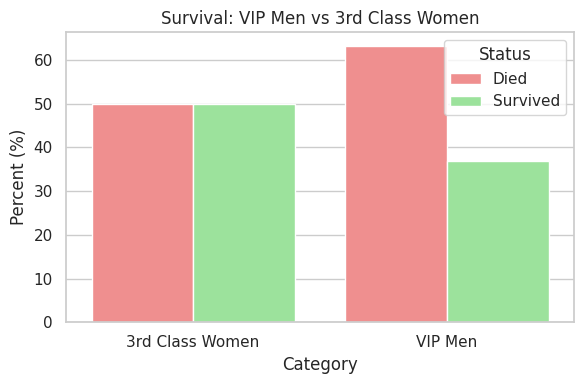

In [ ]:
df_comp = df[
    ((df['Sex'] == 'male') & (df['Fare_Category'] == 'VIP')) |
    ((df['Sex'] == 'female') & (df['Pclass'] == 3))
].copy()

df_comp['Category'] = df_comp.apply(
    lambda r: 'VIP Men' if r['Sex'] == 'male' else '3rd Class Women', axis=1
)

comp_survival = df_comp.groupby(['Category', 'Status']).size().reset_index(name='Count')
comp_survival['Percent'] = 100 * comp_survival['Count'] / comp_survival.groupby('Category')['Count'].transform('sum')

plt.figure(figsize=(6, 4))
sns.barplot(
    data=comp_survival,
    x='Category',
    y='Percent',
    hue='Status',
    palette=['#ff7f7f', '#90ee90']
)
plt.title('Survival: VIP Men vs 3rd Class Women')
plt.ylabel('Percent (%)')
plt.tight_layout()
plt.show()

### 4.3. Вплив розміру родини на виживання

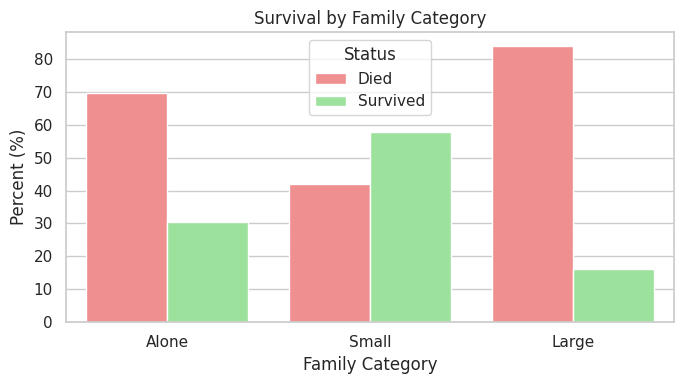

In [ ]:
family_survival = df.groupby(['FamilyCategory', 'Status']).size().reset_index(name='Count')
family_survival['Percent'] = 100 * family_survival['Count'] / family_survival.groupby('FamilyCategory')['Count'].transform('sum')

plt.figure(figsize=(7, 4))
sns.barplot(
    data=family_survival,
    x='FamilyCategory',
    y='Percent',
    hue='Status',
    order=['Alone', 'Small', 'Large'],
    palette=['#ff7f7f', '#90ee90']
)
plt.title('Survival by Family Category')
plt.ylabel('Percent (%)')
plt.xlabel('Family Category')
plt.tight_layout()
plt.show()

### 4.4. Локація та висота палуб (Deck)

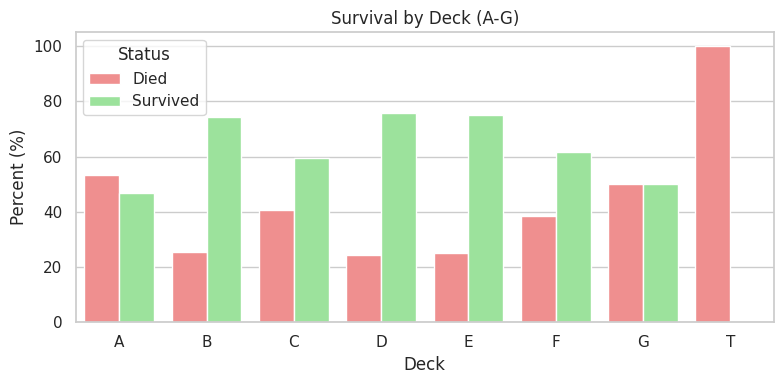

In [ ]:
deck_df = df[df['Deck'] != 'Unknown'].copy()
deck_survival = deck_df.groupby(['Deck', 'Status']).size().reset_index(name='Count')
deck_survival['Percent'] = 100 * deck_survival['Count'] / deck_survival.groupby('Deck')['Count'].transform('sum')

plt.figure(figsize=(8, 4))
sns.barplot(
    data=deck_survival,
    x='Deck',
    y='Percent',
    hue='Status',
    order=sorted(deck_df['Deck'].unique()),
    palette=['#ff7f7f', '#90ee90']
)
plt.title('Survival by Deck (A-G)')
plt.ylabel('Percent (%)')
plt.xlabel('Deck')
plt.tight_layout()
plt.show()

# 5. Фінальний вигляд датасету

In [ ]:
cleaned_df = df.drop(columns=['PassengerId', 'SibSp', 'Parch', 'Is_Alone'])
cleaned_df.head(10)

,Survived,Pclass,Name,Sex,Age,Ticket,Fare,Embarked,Has_cabin,Deck,Title,Family_Size,AloneStatus,FamilyCategory,AgeGroup,Fare_Per_Person,Fare_Category,Status
0,0,3,"Braund, Mr. Owen Harris",male,22.0,A/5 21171,7.2500,S,False,Unknown,Mr,2,With someone,Small,Adult,3.62500,Low,Died
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,PC 17599,71.2833,C,True,C,Mrs,2,With someone,Small,Adult,35.64165,VIP,Survived
2,1,3,"Heikkinen, Miss. Laina",female,26.0,STON/O2. 3101282,7.9250,S,False,Unknown,Miss,1,Alone,Alone,Adult,7.92500,Medium,Survived
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,113803,53.1000,S,True,C,Mrs,2,With someone,Small,Adult,26.55000,VIP,Survived
4,0,3,"Allen, Mr. William Henry",male,35.0,373450,8.0500,S,False,Unknown,Mr,1,Alone,Alone,Adult,8.05000,Medium,Died
5,0,3,"Moran, Mr. James",male,26.0,330877,8.4583,Q,False,Unknown,Mr,1,Alone,Alone,Adult,8.45830,High,Died
6,0,1,"McCarthy, Mr. Timothy J",male,54.0,17463,51.8625,S,True,E,Mr,1,Alone,Alone,Adult,51.86250,VIP,Died
7,0,3,"Palsson, Master. Gosta Leonard",male,2.0,349909,21.0750,S,False,Unknown,Master,5,With someone,Large,Child,4.21500,Low,Died
8,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,347742,11.1333,S,False,Unknown,Mrs,3,With someone,Small,Adult,3.71110,Low,Survived
9,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,237736,30.0708,C,False,Unknown,Mrs,2,With someone,Small,Teen,15.03540,High,Survived


# 6. Висновки дослідження
1. **Кодекс честі священників та офіцерів:** Священники (`Clergy`) продемонстрували найвищу смертність (100% загиблих), оскільки вони добровільно поступалися місцями у рятувальних шлюпках та залишалися проводити службу з приреченими пасажирами на палубі. Офіцери також мали значно менший відсоток порятунку порівняно зі звичайними пасажирами 1-го класу.
2. **Гендерний пріоритет проти фінансового:** Навіть жінки з 3-го класу (найдешевші квитки) мали вищу ймовірність виживання (~50%), ніж чоловіки з найдорожчими квитками категорії VIP (~35-40%). Це доводить пріоритет морського правила «жінки та діти — вперед» над рівнем статків.
3. **Фактор сім'ї:** Найкращі шанси на порятунок мали невеликі сім'ї (`Small`, 2–4 особи). Натомість великі родини (`Large`, 5+ осіб) мали критично низьку виживаність через хаос, необхідність збору всіх родичів та брак місць у шлюпці для великої групи.
4. **Палуби кают:** Пасажири середніх і верхніх ярусів (B, C, D, E) мали суттєво більше шансів на порятунок порівняно з тими, у кого каюта була відсутня або розташовувалася на найнижчих рівнях корабля.